In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/mashlyn/online-retail-ii-uci/online_retail_II.csv
/kaggle/input/datasets/mashlyn/online-retail-ii-uci/online_retail_II.csv


In [2]:
import pandas as pd
import numpy as np

# Load the dataset
file_path = "/kaggle/input/datasets/mashlyn/online-retail-ii-uci/online_retail_II.csv"

df = pd.read_csv(file_path)

# Display basic information
print("Dataset loaded successfully!")
print("-" * 50)

print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
--------------------------------------------------
Number of rows: 1,067,371
Number of columns: 8

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

First 5 rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [3]:
# ==========================================
# STEP 2: DATA QUALITY ANALYSIS
# ==========================================

import pandas as pd
import numpy as np

# 1. Check data types and missing values
print("1. MISSING VALUES")
print("=" * 50)

missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing.sort_values("Missing Percentage", ascending=False))


# 2. Check duplicate rows
print("\n2. DUPLICATE RECORDS")
print("=" * 50)

print("Duplicate rows:", df.duplicated().sum())


# 3. Check cancelled invoices
print("\n3. CANCELLED INVOICES")
print("=" * 50)

cancelled = df["Invoice"].astype(str).str.startswith("C")
print("Rows with cancelled invoice numbers:", cancelled.sum())


# 4. Check invalid quantities
print("\n4. QUANTITY CHECK")
print("=" * 50)

print("Zero or negative quantities:", (df["Quantity"] <= 0).sum())
print("Positive quantities:", (df["Quantity"] > 0).sum())


# 5. Check invalid prices
print("\n5. PRICE CHECK")
print("=" * 50)

print("Zero or negative prices:", (df["Price"] <= 0).sum())
print("Positive prices:", (df["Price"] > 0).sum())


# 6. Check date range
print("\n6. DATE RANGE")
print("=" * 50)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

print("Earliest transaction:", df["InvoiceDate"].min())
print("Latest transaction:", df["InvoiceDate"].max())


# 7. Basic descriptive statistics
print("\n7. NUMERICAL SUMMARY")
print("=" * 50)

display(df[["Quantity", "Price"]].describe())

1. MISSING VALUES


,Missing Count,Missing Percentage
Customer ID,243007,22.77
Description,4382,0.41
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00



2. DUPLICATE RECORDS
Duplicate rows: 34335

3. CANCELLED INVOICES
Rows with cancelled invoice numbers: 19494

4. QUANTITY CHECK
Zero or negative quantities: 22950
Positive quantities: 1044421

5. PRICE CHECK
Zero or negative prices: 6207
Positive prices: 1061164

6. DATE RANGE
Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2011-12-09 12:50:00

7. NUMERICAL SUMMARY


,Quantity,Price
count,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00
std,1.727058e+02,1.235531e+02
min,-8.099500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,8.099500e+04,3.897000e+04


In [4]:
# ==========================================
# STEP 3: CLEAN THE RETAIL DATA
# ==========================================

# Preserve the original dataset
df_clean = df.copy()

initial_rows = len(df_clean)

# 1. Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# 2. Remove rows without a Customer ID
df_clean = df_clean.dropna(subset=["Customer ID"])

# 3. Remove cancelled invoices
# Invoice numbers beginning with C indicate cancellations
is_cancelled = (
    df_clean["Invoice"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.startswith("C")
)

df_clean = df_clean.loc[~is_cancelled].copy()

# 4. Keep only positive quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
].copy()

# 5. Ensure dates are valid
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

df_clean = df_clean.dropna(subset=["InvoiceDate"])

# 6. Create transaction revenue
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["Price"]
)

# Summary
print("CLEANING SUMMARY")
print("=" * 45)
print(f"Original rows: {initial_rows:,}")
print(f"Remaining rows: {len(df_clean):,}")
print(f"Rows removed: {initial_rows - len(df_clean):,}")
print(f"Customers remaining: {df_clean['Customer ID'].nunique():,}")
print(f"Unique invoices: {df_clean['Invoice'].nunique():,}")
print(f"Total revenue: {df_clean['Revenue'].sum():,.2f}")

print("\nFirst five cleaned rows:")
display(df_clean.head())

CLEANING SUMMARY
Original rows: 1,067,371
Remaining rows: 779,425
Rows removed: 287,946
Customers remaining: 5,878
Unique invoices: 36,969
Total revenue: 17,374,804.27

First five cleaned rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [5]:
# ==========================================
# STEP 4: RFM ANALYSIS
# ==========================================

# Set the reference date to one day after
# the final transaction in the dataset.
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

print("RFM reference date:", snapshot_date)


# Calculate customer-level RFM metrics
rfm = (
    df_clean.groupby("Customer ID")
    .agg(
        Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
        Frequency=("Invoice", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)


# Display the first 10 customers
print("\nFirst 10 customers — RFM metrics")
display(rfm.head(10))


# Summary statistics
print("\nRFM summary statistics")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))


# Check the number of customers
print("\nTotal customers in RFM table:", len(rfm))

RFM reference date: 2011-12-10 12:50:00

First 10 customers — RFM metrics


,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40
5,12351.0,375,1,300.93
6,12352.0,36,10,2849.84
7,12353.0,204,2,406.76
8,12354.0,232,1,1079.40
9,12355.0,214,2,947.61



RFM summary statistics


,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,201.33,6.29,2955.90
std,209.34,13.01,14440.85
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,2248.30
max,739.00,398.00,580987.04



Total customers in RFM table: 5878


In [6]:
# ==========================================
# STEP 5: RFM SCORING
# ==========================================

# Score each metric from 1 to 5 using quintiles.
# Recency is reversed because lower recency is better.

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine the three scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

# Inspect the results
print("RFM scores assigned successfully!")
display(rfm.head(15))

print("\nScore distributions:")
for col in ["R_Score", "F_Score", "M_Score"]:
    print(f"\n{col}")
    display(rfm[col].value_counts().sort_index())

RFM scores assigned successfully!


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,12,77556.46,2,5,5,255
1,12347.0,2,8,4921.53,5,4,5,545
2,12348.0,75,5,2019.40,3,4,4,344
3,12349.0,19,4,4428.69,5,3,5,535
4,12350.0,310,1,334.40,2,1,2,212
5,12351.0,375,1,300.93,2,1,2,212
6,12352.0,36,10,2849.84,4,5,4,454
7,12353.0,204,2,406.76,2,2,2,222
8,12354.0,232,1,1079.40,2,1,3,213
9,12355.0,214,2,947.61,2,2,3,223



Score distributions:

R_Score


R_Score
1    1176
2    1175
3    1176
4    1175
5    1176
Name: count, dtype: int64


F_Score


F_Score
1    1176
2    1175
3    1176
4    1175
5    1176
Name: count, dtype: int64


M_Score


M_Score
1    1176
2    1175
3    1176
4    1175
5    1176
Name: count, dtype: int64

In [7]:
# ==========================================
# STEP 6: CUSTOMER SEGMENTATION
# ==========================================

def segment_customer(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    # Champions: recent, frequent, high-spending customers
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    # Loyal: frequent customers with good spending scores
    elif f >= 4 and m >= 3:
        return "Loyal Customers"

    # Potential loyalists: recent customers with promising scores
    elif r >= 4 and f >= 2:
        return "Potential Loyalists"

    # Recent customers: very recent, low-frequency buyers
    elif r >= 4 and f <= 2:
        return "Recent Customers"

    # At risk: previously valuable customers who have not purchased recently
    elif r <= 2 and (f >= 3 or m >= 4):
        return "At Risk"

    # Remaining customers
    else:
        return "Lost / Hibernating"


rfm["Segment"] = rfm.apply(segment_customer, axis=1)

print("Customer segments created successfully!")
display(rfm.head(10))

print("\nNumber of customers in each segment:")
display(
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customers")
)

Customer segments created successfully!


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,326,12,77556.46,2,5,5,255,Loyal Customers
1,12347.0,2,8,4921.53,5,4,5,545,Champions
2,12348.0,75,5,2019.40,3,4,4,344,Loyal Customers
3,12349.0,19,4,4428.69,5,3,5,535,Potential Loyalists
4,12350.0,310,1,334.40,2,1,2,212,Lost / Hibernating
5,12351.0,375,1,300.93,2,1,2,212,Lost / Hibernating
6,12352.0,36,10,2849.84,4,5,4,454,Champions
7,12353.0,204,2,406.76,2,2,2,222,Lost / Hibernating
8,12354.0,232,1,1079.40,2,1,3,213,Lost / Hibernating
9,12355.0,214,2,947.61,2,2,3,223,Lost / Hibernating



Number of customers in each segment:


,Segment,Customers
0,Lost / Hibernating,2144
1,Champions,1289
2,Loyal Customers,985
3,Potential Loyalists,733
4,At Risk,560
5,Recent Customers,167


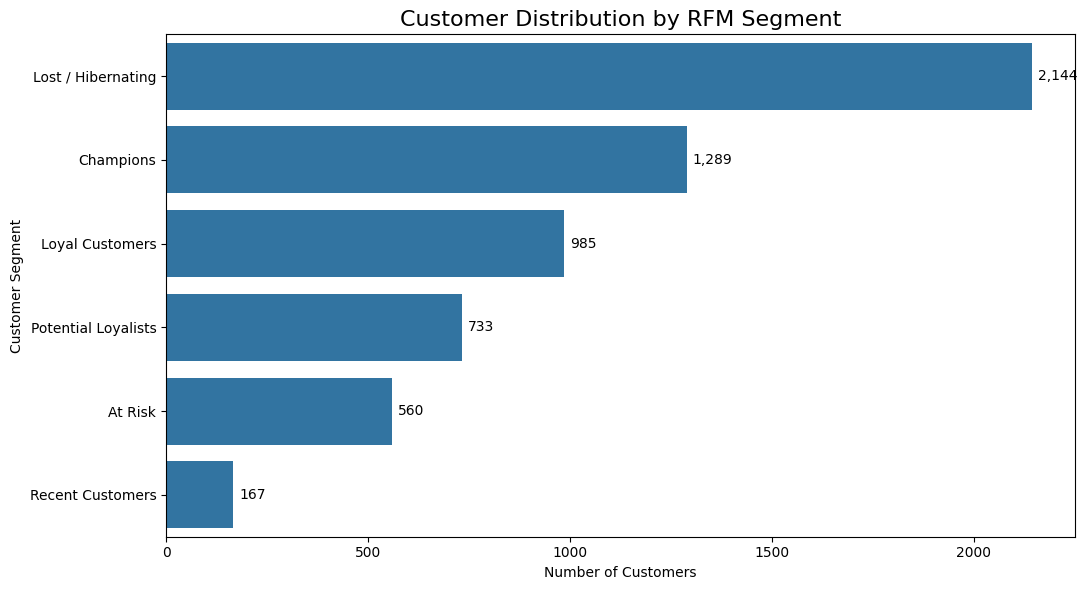

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count customers in each segment
segment_counts = (
    rfm["Segment"]
    .value_counts()
    .sort_values(ascending=False)
)

# Plot the distribution
plt.figure(figsize=(11, 6))

sns.barplot(
    x=segment_counts.values,
    y=segment_counts.index
)

plt.title("Customer Distribution by RFM Segment", fontsize=16)
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

for i, value in enumerate(segment_counts.values):
    plt.text(value + 15, i, f"{value:,}", va="center")

plt.tight_layout()
plt.show()

In [9]:
# ==========================================
# STEP 10: REVENUE ANALYSIS BY SEGMENT
# ==========================================

segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customers=("Customer ID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
        Total_Revenue=("Monetary", "sum")
    )
    .reset_index()
)

# Calculate the share of customers and revenue
segment_summary["Customer_Share_%"] = (
    segment_summary["Customers"] / len(rfm) * 100
)

segment_summary["Revenue_Share_%"] = (
    segment_summary["Total_Revenue"]
    / segment_summary["Total_Revenue"].sum()
    * 100
)

# Sort from highest to lowest revenue
segment_summary = segment_summary.sort_values(
    "Total_Revenue",
    ascending=False
)

display(segment_summary.round(2))

,Segment,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Share_%,Revenue_Share_%
1,Champions,1289,19.72,17.15,9169.61,11819626.88,21.93,68.03
3,Loyal Customers,985,169.81,7.92,2998.32,2953346.09,16.76,17.00
2,Lost / Hibernating,2144,348.77,1.55,481.55,1032438.45,36.47,5.94
4,Potential Loyalists,733,25.52,2.67,1124.77,824455.86,12.47,4.75
0,At Risk,560,391.70,2.90,1230.92,689316.57,9.53,3.97
5,Recent Customers,167,29.55,1.00,333.06,55620.42,2.84,0.32


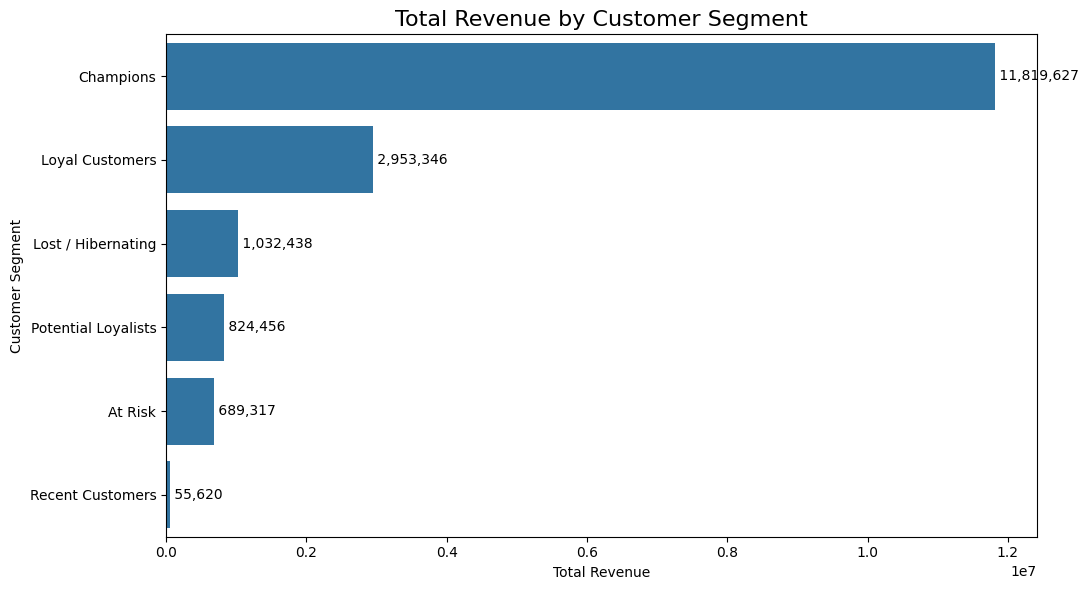

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

revenue_plot = segment_summary.sort_values(
    "Total_Revenue",
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=revenue_plot,
    x="Total_Revenue",
    y="Segment"
)

plt.title("Total Revenue by Customer Segment", fontsize=16)
plt.xlabel("Total Revenue")
plt.ylabel("Customer Segment")

for i, value in enumerate(revenue_plot["Total_Revenue"]):
    plt.text(value, i, f" {value:,.0f}", va="center")

plt.tight_layout()
plt.show()

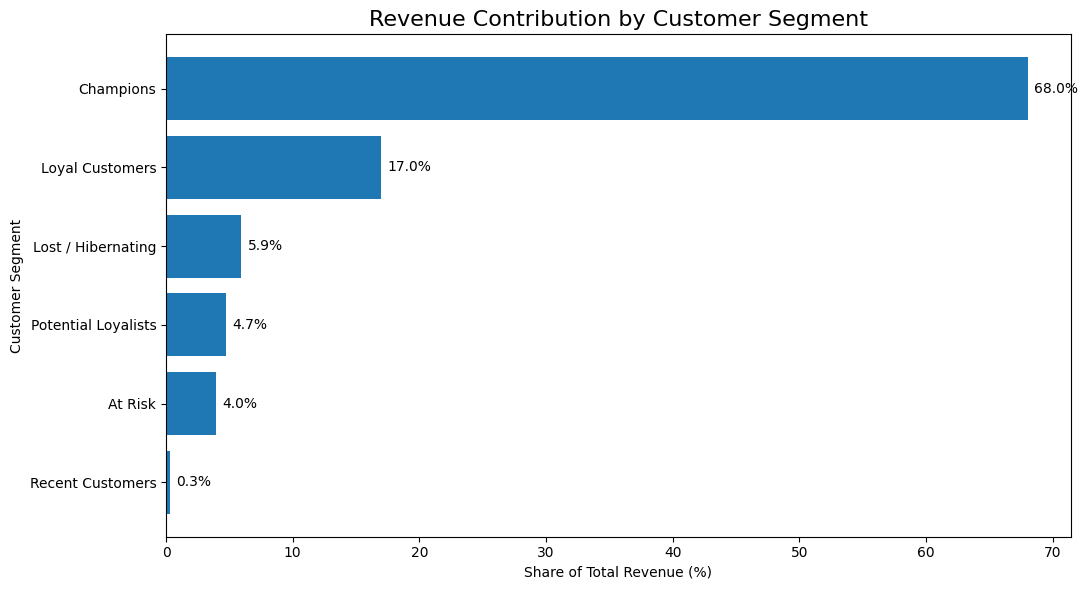

In [11]:
import matplotlib.pyplot as plt

# Calculate revenue share by segment
revenue_share = segment_summary.sort_values(
    "Revenue_Share_%",
    ascending=True
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    revenue_share["Segment"],
    revenue_share["Revenue_Share_%"]
)

plt.title(
    "Revenue Contribution by Customer Segment",
    fontsize=16
)
plt.xlabel("Share of Total Revenue (%)")
plt.ylabel("Customer Segment")

for bar, value in zip(bars, revenue_share["Revenue_Share_%"]):
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()